# Portfolio sintetico single-pass: local greedy + SCIP

Questo notebook analizza esclusivamente artifact gia` pubblicati dal runner interno. Non costruisce il problema e non invoca la pipeline QReduce.

Prima di eseguirlo, installare le dipendenze opzionali e pubblicare il run corrispondente:

```bash
poetry install --with notebooks,experiments
poetry run python -m qreduce.experiments.portfolio \
  --run-id 002_scip \
  --asset-count 12 \
  --mis-solver-id local_greedy \
  --classical-solver-id scip \
  --model-export
```

Il backend MIS `local_greedy` e` locale e dependency-free. SCIP richiede il binding PySCIPOpt; se non disponibile, il runner pubblica comunque un artifact con failure normalizzata.


In [6]:
from pathlib import Path

from qreduce.experiments.portfolio import load_synthetic_portfolio_analysis
from qreduce.notebooks.plots import plot_correlation_matrix, plot_reduction_graph
from qreduce.notebooks.presentation import display_records, display_vertical

repository_root = next(
    (
        directory
        for directory in (Path.cwd(), *Path.cwd().parents)
        if (directory / "pyproject.toml").is_file()
    ),
    None,
)
if repository_root is None:
    raise RuntimeError("Run this notebook from inside the QReduce repository.")

run_directory = repository_root / "outputs/002_scip"
analysis = load_synthetic_portfolio_analysis(run_directory)
artifacts = analysis.artifacts
config = artifacts.config
result = artifacts.result


## 1. Configurazione e provenance del run

Le tabelle riportano la configurazione richiesta, lo stato normalizzato e il manifest dell'artifact pubblicato.


In [7]:
run_configuration = {
    "run_directory": str(run_directory),
    "mis_solver_id": config["mis_solver_id"],
    "mis_provider_parameters": config["mis_execution"]["provider_parameters"],
    "classical_solver_id": config["classical_solve"]["classical_solver_id"],
    "run_status": result["run_result"]["run_status"],
    "pipeline_stage": result["run_result"]["stage"],
    "terminal_reason": result["run_result"]["terminal_reason"],
}
display_vertical(run_configuration, title="Configurazione richiesta e stato normalizzato")
display_vertical(dict(artifacts.manifest), title="Manifest dell'artifact")


Configurazione richiesta e stato normalizzato


,campo,valore
0,run_directory,/Users/trivellatoa/DATADIR/Programmazione/pyth...
1,mis_solver_id,local_greedy
2,mis_provider_parameters,{}
3,classical_solver_id,scip
4,run_status,success
5,pipeline_stage,postcheck
6,terminal_reason,NaN


Manifest dell'artifact


,campo,valore
0,artifact_schema_version,1.1
1,config_hash,e63b96f428412192d3f1dba8a31291d367b175399d1e53...
2,created_at,2026-11-13T17:10:45.307009Z
3,experiment_id,synthetic-portfolio-single-pass
4,files,"{\n ""config_used.json"": ""e63b96f428412192d3f1..."
5,fixing_manifest,"{\n ""entries"": [\n {\n ""fixing_origin..."
6,has_reduction,True
7,is_classical_only,False
8,model_export,"{\n ""external"": false,\n ""format"": ""lp"",\n ..."
9,policy_provenance,"{\n ""declared_instance_class"": null,\n ""decl..."


## 2. Grafo di riduzione e correlazioni persistite

Il grafo e la matrice derivano dagli artifact. Il layout del grafo e` illustrativo e non rappresenta coordinate geometriche del problema.


,asset,campo,valore
0,asset-1,asset,asset-000
1,asset-1,retention_score,0.504993
2,asset-2,asset,asset-001
3,asset-2,retention_score,0.54989
4,asset-3,asset,asset-002
5,asset-3,retention_score,0.618919
6,asset-4,asset,asset-003
7,asset-4,retention_score,0.719455
8,asset-5,asset,asset-004
9,asset-5,retention_score,0.770521


,arco,campo,valore


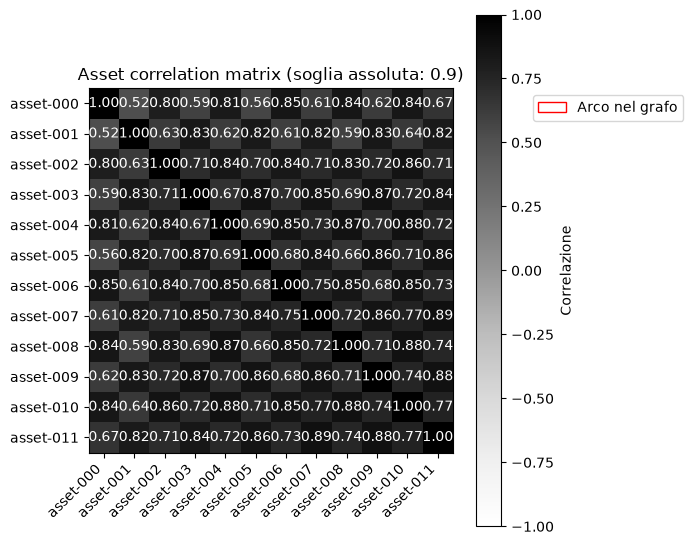

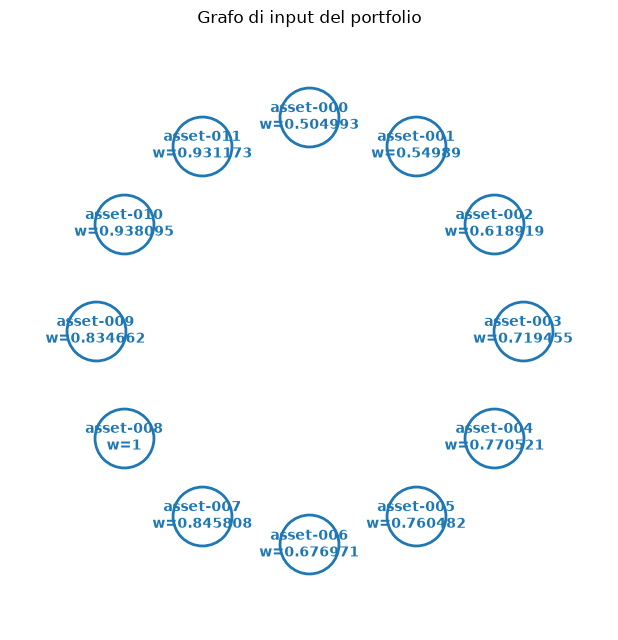

In [8]:
display_records(analysis.node_rows(), record_label="asset")
display_records(analysis.edge_rows(), record_label="arco")

%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plot_correlation_matrix(
    analysis.asset_ids,
    analysis.correlation,
    analysis.graph,
    analysis.correlation_threshold,
)
plt.show()

fig, ax = plot_reduction_graph(analysis.graph, title="Grafo di input del portfolio")
plt.show()


## 3. Stato e metriche della pipeline

Lo stato finale e le metriche descrivono l'esecuzione pubblicata; non costituiscono da soli una decisione di adozione.


In [9]:
display_vertical(result["run_result"], title="Risultato normalizzato della pipeline")
display_vertical(result["metrics"], title="Metriche del run")


Risultato normalizzato della pipeline


,campo,valore
0,adoption_status,adopted
1,classical_solver_status,optimal
2,config_hash,e63b96f428412192d3f1dba8a31291d367b175399d1e53...
3,diagnostic_message,NaN
4,input_hash,18855aa5f45df76498d75418a3c91bc7a7b41dac9b51df...
5,policy_hash,NaN
6,postcheck_status,passed
7,round_results,"[\n {\n ""metadata"": {\n ""excluded_cou..."
8,run_id,002_scip
9,run_status,success


Metriche del run


,campo,valore
0,cumulative_reduction_ratio,0.416667
1,end_to_end_runtime_seconds,0.050685
2,recovery_attempt_count,0.000000
3,round_count,1.000000


## 4. Compilation ed esecuzione MIS

La compilation e l'esecuzione sono mostrate separatamente. Le sample MIS servono a costruire il dominio candidato e non sono la soluzione finale del portfolio.


In [10]:
round_result = analysis.single_pass_result
compilation = round_result["mis_compilation_result"]
execution = round_result["mis_execution_result"]
if compilation is None or execution is None:
    raise RuntimeError("The published run did not persist both MIS compilation and execution results.")

compiled_job = compilation.get("compiled_job") or {}
compilation_summary = {
    "completion_status": compilation["completion_status"],
    "requested_provider_id": compilation["requested_provider_id"],
    "requested_backend_id": compilation["requested_backend_id"],
    "effective_provider_id": compilation["effective_provider_id"],
    "effective_backend_id": compilation["effective_backend_id"],
    "compiled_job_id": compiled_job.get("compiled_job_id"),
    "problem_form": compiled_job.get("problem_form"),
    "runtime_seconds": compilation["runtime_seconds"],
    "terminal_reason": compilation["terminal_reason"],
    "diagnostic_message": compilation["diagnostic_message"],
    "effective_compilation_parameters": compilation["effective_compilation_parameters"],
}
execution_summary = {
    field: execution[field]
    for field in (
        "completion_status",
        "requested_provider_id",
        "requested_backend_id",
        "effective_provider_id",
        "effective_backend_id",
        "effective_device_id",
        "backend_family",
        "execution_mode",
        "runtime_seconds",
        "terminal_reason",
        "diagnostic_message",
        "effective_execution_parameters",
    )
}
display_vertical(compilation_summary, title="Compilation MIS")
display_vertical(execution_summary, title="Esecuzione MIS")
display_records(round_result["selected_mis_samples"], record_label="sample")


Compilation MIS


,campo,valore
0,completion_status,completed
1,requested_provider_id,local
2,requested_backend_id,greedy_mis
3,effective_provider_id,local
4,effective_backend_id,greedy_mis
5,compiled_job_id,002_scip:round:0:local-greedy
6,problem_form,mis_graph
7,runtime_seconds,0.000005
8,terminal_reason,None
9,diagnostic_message,None


Esecuzione MIS


,campo,valore
0,completion_status,completed
1,requested_provider_id,local
2,requested_backend_id,greedy_mis
3,effective_provider_id,local
4,effective_backend_id,greedy_mis
5,effective_device_id,None
6,backend_family,classical_heuristic
7,execution_mode,local
8,runtime_seconds,0.000034
9,terminal_reason,None


,sample,campo,valore
0,002_scip:round:0:local-greedy:sample:0000,backend_reported_score,None
1,002_scip:round:0:local-greedy:sample:0000,backend_reported_score_kind,unavailable
2,002_scip:round:0:local-greedy:sample:0000,canonical_ising_energy,-9.15097
3,002_scip:round:0:local-greedy:sample:0000,canonical_qubo_energy,-9.15097
4,002_scip:round:0:local-greedy:sample:0000,delta,"[\n 1,\n 1,\n 1,\n 1,\n 1,\n 1,\n 1,\n ..."
5,002_scip:round:0:local-greedy:sample:0000,effective_compilation_parameters,{}
6,002_scip:round:0:local-greedy:sample:0000,effective_execution_parameters,{}
7,002_scip:round:0:local-greedy:sample:0000,execution_runtime_seconds,0.000018
8,002_scip:round:0:local-greedy:sample:0000,is_independent_set,True
9,002_scip:round:0:local-greedy:sample:0000,node_order,"[\n ""asset-000"",\n ""asset-001"",\n ""asset-00..."


## 5. Dominio candidato e fixing

Il colore nel grafo identifica il dominio mantenuto dopo la riduzione. Gli asset esclusi ricevono fixing nel problema classico residuo.


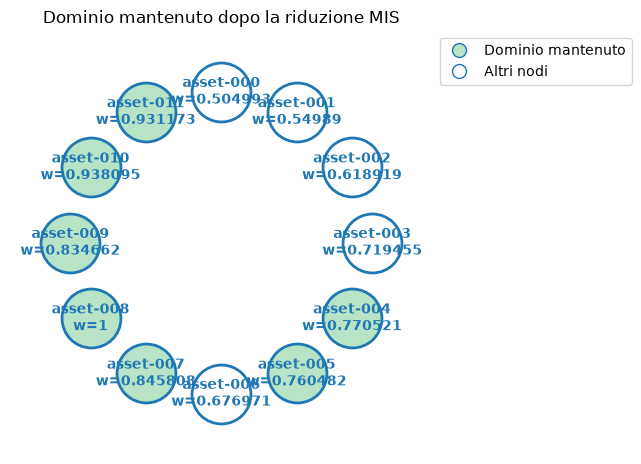

,asset,campo,valore
0,asset-1,asset,asset-000
1,asset-1,retained,False
2,asset-2,asset,asset-001
3,asset-2,retained,False
4,asset-3,asset,asset-002
5,asset-3,retained,False
6,asset-4,asset,asset-003
7,asset-4,retained,False
8,asset-5,asset,asset-004
9,asset-5,retained,True


Riepilogo fixing


,campo,valore
0,excluded_item_ids,"[\n ""asset-000"",\n ""asset-001"",\n ""asset-00..."
1,origin,heuristic_candidate_domain
2,policy_version,1
3,provenance,"{\n ""graph_policy_id"": ""synthetic-portfolio-n..."
4,retained_item_ids,"[\n ""asset-008"",\n ""asset-010"",\n ""asset-01..."
5,round_index,0
6,source_candidate_ids,"[\n ""candidate:0000""\n]"


,fixing,campo,valore
0,fixing-1,fixing_origin,mis_heuristic
1,fixing-1,guarantee_level,heuristic
2,fixing-1,item_id,asset-000
3,fixing-1,proof_reference,NaN
4,fixing-1,reason,mis_heuristic_exclusion
5,fixing-1,user_request_reference,NaN
6,fixing-1,variable_values,"{\n ""delta__asset-000"": 0.0,\n ""x__asset-000..."
7,fixing-2,fixing_origin,mis_heuristic
8,fixing-2,guarantee_level,heuristic
9,fixing-2,item_id,asset-001


In [11]:
fig, ax = plot_reduction_graph(
    analysis.graph,
    analysis.retained_item_ids,
    highlighted_label="Dominio mantenuto",
    title="Dominio mantenuto dopo la riduzione MIS",
)
plt.show()

display_records(analysis.domain_rows(), record_label="asset")
fixing_manifest = analysis.single_pass_result.get("fixing_manifest")
if fixing_manifest is None:
    display_vertical({"fixing_manifest": None})
else:
    display_vertical(
        {field: value for field, value in fixing_manifest.items() if field != "entries"},
        title="Riepilogo fixing",
    )
    display_records(fixing_manifest["entries"], record_label="fixing")


## 6. Solve classico e post-check indipendente

Il risultato e` adottabile soltanto se il solve classico e il post-check soddisfano i criteri registrati negli artifact.


In [12]:
classical_result = result["classical_result"]
postcheck_result = result["postcheck_result"]
if classical_result is None:
    display_vertical({"classical_result": None})
else:
    display_vertical(classical_result, title="Solve classico")
if postcheck_result is None:
    display_vertical({"postcheck_result": None})
else:
    display_vertical(postcheck_result, title="Post-check indipendente")


Solve classico


,campo,valore
0,best_bound,-0.114403
1,classical_solver_status,optimal
2,constraint_count,2
3,diagnostic_message,None
4,effective_solver_id,scip
5,effective_solver_parameters,"{\n ""random_seed"": 7,\n ""threads"": 1,\n ""ti..."
6,gap,0.0
7,is_optimal,True
8,is_time_limited,False
9,model_export_path,/Users/trivellatoa/DATADIR/Programmazione/pyth...


Post-check indipendente


,campo,valore
0,failure_reasons,[]
1,fixed_variable_compliance,True
2,integrality_compliance,True
3,objective_recomputed,-0.114403
4,original_constraint_compliance,True
5,postcheck_feasible,True
6,solver_objective_compliance,True
7,tolerances_used,"{\n ""integrality_tolerance"": 1e-06,\n ""objec..."


## 7. Interpretazione

Il risultato MIS non certifica l'ottimalita` del problema originale. L'eventuale adozione dipende dal solve classico residuo, dal rispetto dei fixing e dal post-check indipendente. Un backend indisponibile o un solve non adottabile resta comunque analizzabile tramite gli artifact pubblicati.
